<a href="https://colab.research.google.com/github/JuanTorresCol/Computer-Vision-Processing-Pipeline-Feature-Extraction-Face-Recognition-Object-Counting/blob/main/Assignment4_JuanTorres.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This code has been ran on November 15th of 2026

In [1]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install -U opencv-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 MB 40.5 MB/s  0:00:01


In [2]:
!pip install opencv-contrib-python-headless==5.0.0.93

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 25.5 MB/s  0:00:02


### Important Note: Restart Runtime After Installation

After running the cell above to install `opencv-contrib-python`, you might need to restart your Colab runtime for the changes to fully take effect. You can do this by going to `Runtime > Restart runtime` in the Colab menu. Once the runtime has restarted, please re-run all cells, starting from the imports, to ensure everything is loaded correctly.

**Part 1- Feature extraction**

In [3]:
#Start with uploading the required images on Google drive
import cv2
import matplotlib.pyplot as plt
import numpy as np
import imutils
from google.colab.patches import cv2_imshow
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

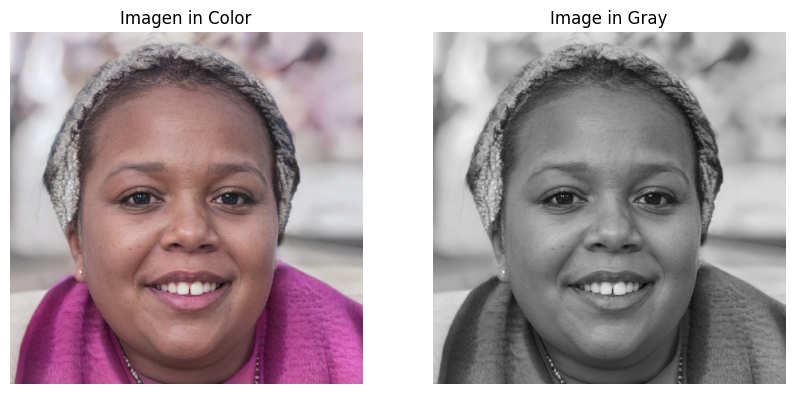

In [14]:
# Read the original image pic1 and create a regular plus a gray version of it.
# The result should be similar to what you see in instrcutions
img_bgr = cv2.imread('Assignment4_pic1.jpg')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

cv2.imwrite('pic1_gray.jpg', img_gray)

f = plt.figure(figsize=(10, 5))
f.add_subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Imagen in Color")
plt.axis('off')

f.add_subplot(1, 2, 2)
plt.imshow(img_gray, cmap='gray')
plt.title("Image in Gray")
plt.axis('off')
plt.show()

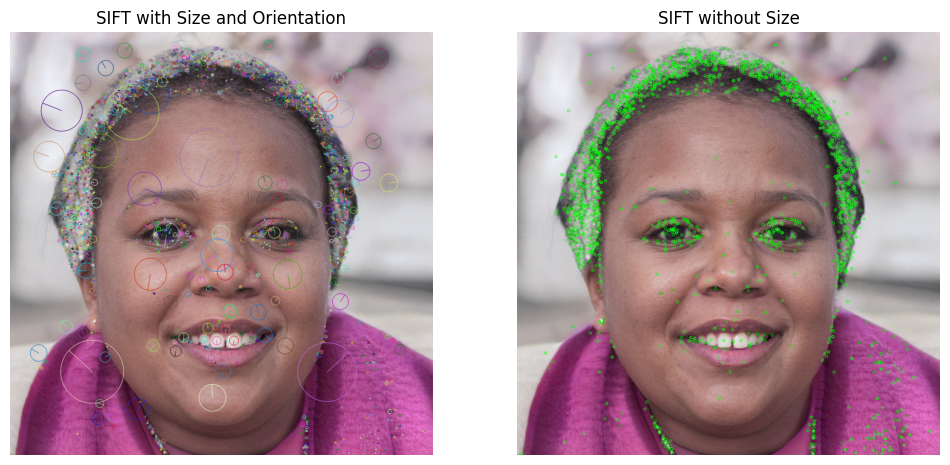

In [16]:
sift = cv2.SIFT_create()
original_keypoints, original_descriptor = sift.detectAndCompute(img_gray, None)

keypoints_without_size = np.copy(img_rgb)
keypoints_with_size = np.copy(img_rgb)

# Draw the results
result1 = cv2.drawKeypoints(img_rgb, original_keypoints, keypoints_with_size, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
result2 = cv2.drawKeypoints(img_rgb, original_keypoints, keypoints_without_size, color=(0, 255, 0))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(result1)
plt.title("SIFT with Size and Orientation")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result2)
plt.title("SIFT without Size")
plt.axis('off')
plt.show()

In [ ]:
# Explain your understanding here

That code snippet sets up and runs the SIFT algorithm to detect keypoints and compute descriptors on a grayscale image.

It then visualizes the results side-by-side in two ways: one with rich visual markers showing each keypoint's scale and orientation using circles, and another displaying simple points without size information. It's a great way to visually check how SIFT captures structural details

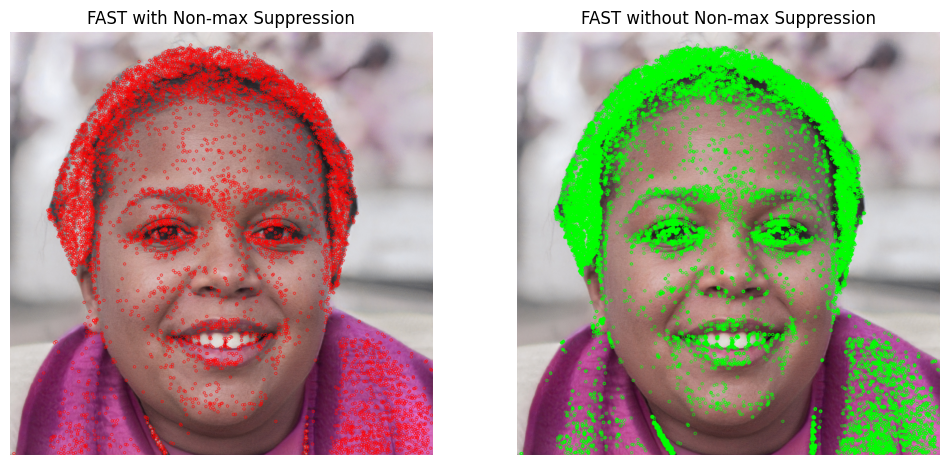

In [17]:
fast = cv2.FastFeatureDetector_create()
keypoints_with_nonmax = fast.detect(img_gray, None)

fast.setNonmaxSuppression(False)
keypoints_without_nonmax = fast.detect(img_gray, None)

image_with_nonmax = np.copy(img_rgb)
image_without_nonmax = np.copy(img_rgb)

result_fast1 = cv2.drawKeypoints(img_rgb, keypoints_with_nonmax, image_with_nonmax, color=(255, 0, 0))
result_fast2 = cv2.drawKeypoints(img_rgb, keypoints_without_nonmax, image_without_nonmax, color=(0, 255, 0))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(result_fast1)
plt.title("FAST with Non-max Suppression")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_fast2)
plt.title("FAST without Non-max Suppression")
plt.axis('off')
plt.show()

In [ ]:
# Explain your understanding here:


That code snippet compares the FAST corner detector with and without non-max suppression.

When non-max suppression is on (default), it gives you clean, distinct points for each corner. But when you turn it off, you get these thick clusters of overlapping points around the same spots because it keeps every single candidate it finds. Basically, it shows how suppression cleans up redundant detections


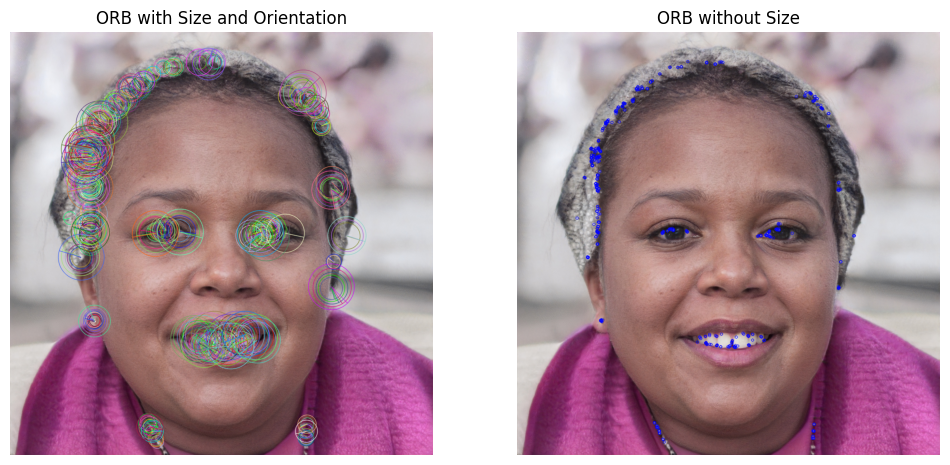

In [18]:
orb = cv2.ORB_create()
original_keypoints, original_descriptor = orb.detectAndCompute(img_gray, None)
query_keypoints, query_descriptor = orb.detectAndCompute(img_gray, None)

keypoints_without_size = np.copy(img_rgb)
keypoints_with_size = np.copy(img_rgb)

result_orb1 = cv2.drawKeypoints(img_rgb, original_keypoints, keypoints_with_size, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
result_orb2 = cv2.drawKeypoints(img_rgb, original_keypoints, keypoints_without_size, color=(0, 0, 255))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(result_orb1)
plt.title("ORB with Size and Orientation")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_orb2)
plt.title("ORB without Size")
plt.axis('off')
plt.show()

In [ ]:
# Explain your understanding here:

That code snippet sets up and runs the ORB algorithm to detect keypoints and compute binary descriptors on a grayscale image. It then visualizes the results side-by-side in two ways: one with rich visual markers showing each keypoint's scale and orientation using circles, and another displaying simple points without size information. It's a great way to visually check how ORB captures efficient structural features

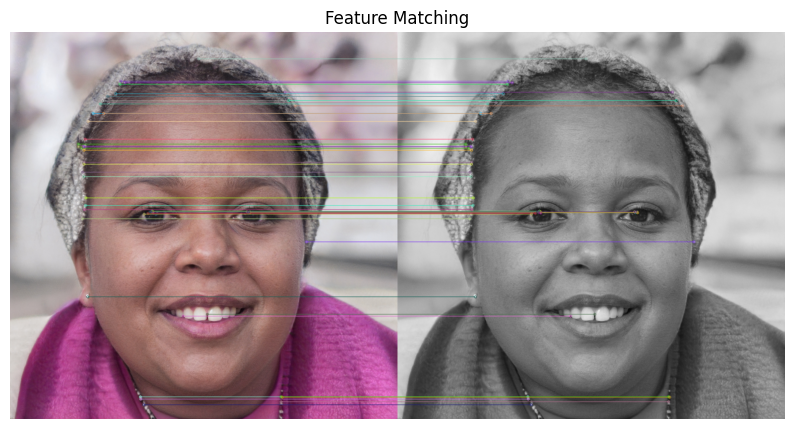

The number of matching keypoints between the original and the query image is 500



In [19]:
brute_force = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = brute_force.match(original_descriptor, query_descriptor)
matches = sorted(matches, key=lambda x: x.distance)

result = cv2.drawMatches(img_rgb, original_keypoints, cv2.imread('pic1_gray.jpg'), query_keypoints, matches[:50], None, flags=2)

plt.figure(figsize=(10, 6))
plt.imshow(result)
plt.title("Feature Matching")
plt.axis('off')
plt.show()

print("The number of matching keypoints between the original and the query image is {}\n".format(len(matches)))

In [ ]:
# Explain your understanding here. What is the goal of this matching point?

That code snippet performs feature matching between image descriptors using a Brute-Force Matcher with Hamming distance. It calculates the matches, sorts them by distance quality, draws lines connecting the top matching points side-by-side, and prints out the total number of valid matches found between the images.

**Part 2- Face recognition**

In [ ]:
face_cascade = cv2.CascadeClassifier()
eye_cascade = cv2.CascadeClassifier()

face_ok = face_cascade.load("/content/haarcascade_frontalface_default.xml")
eye_ok = eye_cascade.load("/content/haarcascade_eye.xml")

img = cv2.imread("/content/Assignment4_pic2.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=5)

    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (0, 255, 0), 2)

cv2_imshow(img)

In [20]:
#b- Working on webcam
#Function to activate your laptop cam. This function is comp;ete and you don't need to do anything.
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

<IPython.core.display.Javascript object>

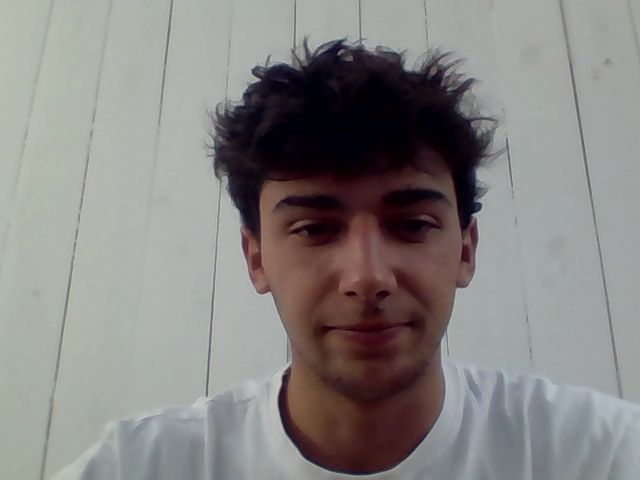

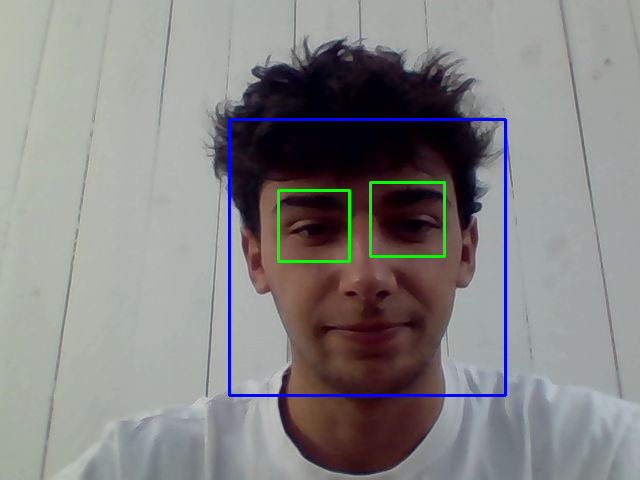

In [25]:
# Open the camera and capture a photo
image_file = take_photo('photo.jpg')

# Read and display the captured image
image = cv2.imread(image_file)
cv2_imshow(image)

# Apply the Haar Cascade classifier to the captured image
gray_cam = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
faces_cam = face_cascade.detectMultiScale(gray_cam, scaleFactor=1.1, minNeighbors=5)

for (x, y, w, h) in faces_cam:
    cv2.rectangle(image, (x, y), (x + w, y + h), (255, 0, 0), 2)
    roi_gray_cam = gray_cam[y:y+h, x:x+w]
    roi_color_cam = image[y:y+h, x:x+w]
    eyes_cam = eye_cascade.detectMultiScale(roi_gray_cam, scaleFactor=1.1, minNeighbors=5)

    for (ex, ey, ew, eh) in eyes_cam:
        cv2.rectangle(roi_color_cam, (ex, ey), (ex + ew, ey + eh), (0, 255, 0), 2)

cv2_imshow(image)

**Part 3- Parameter detection**

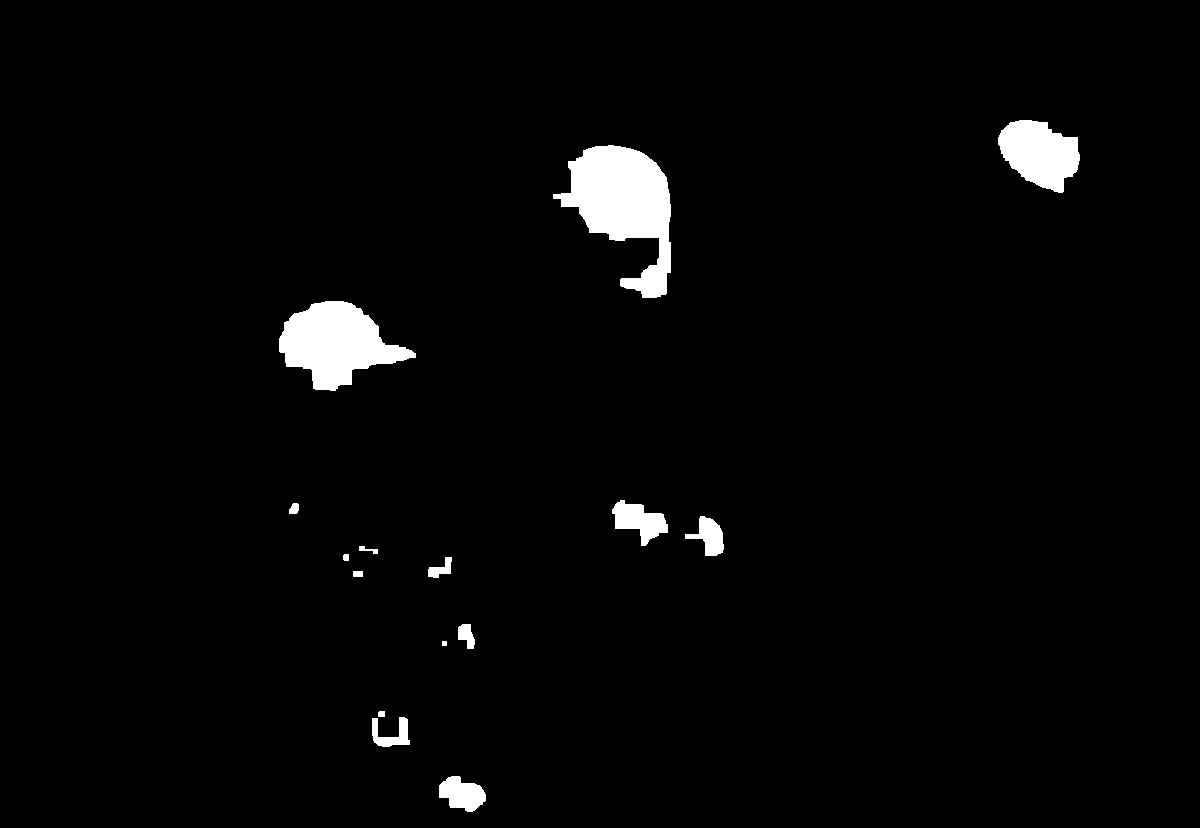

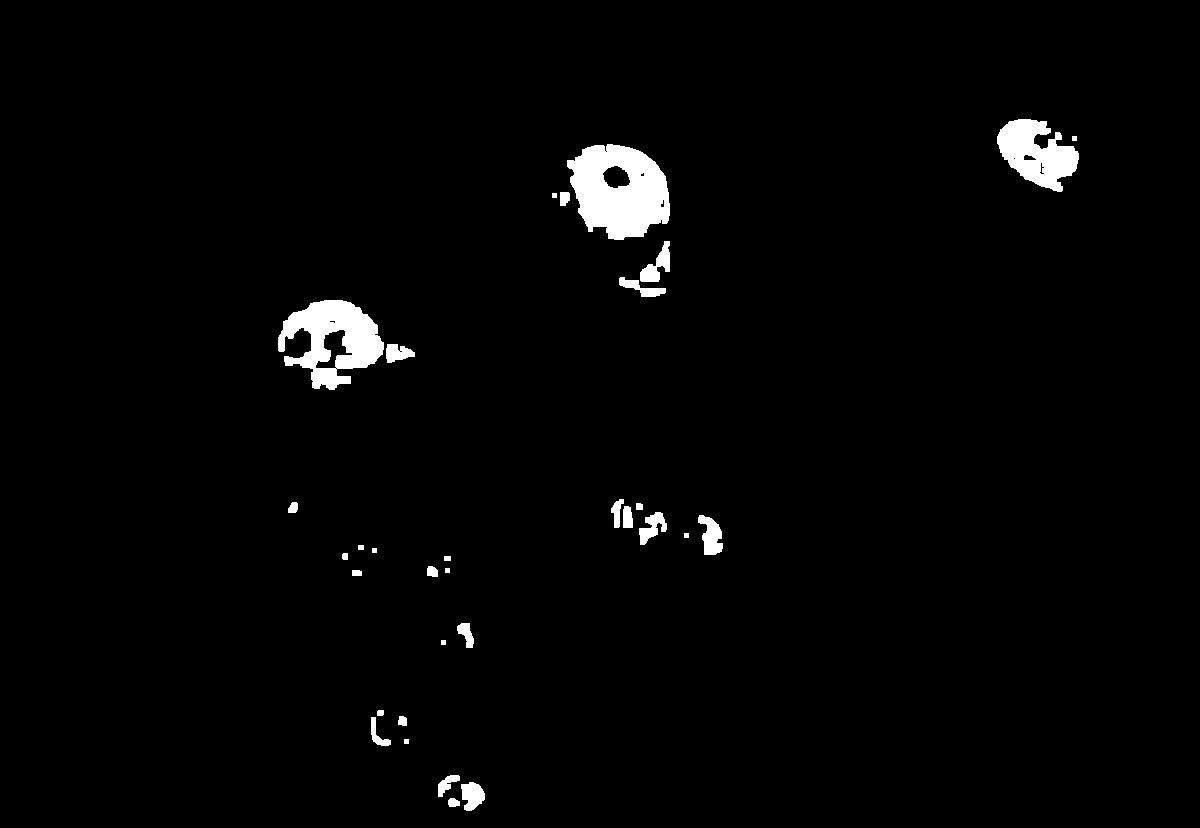

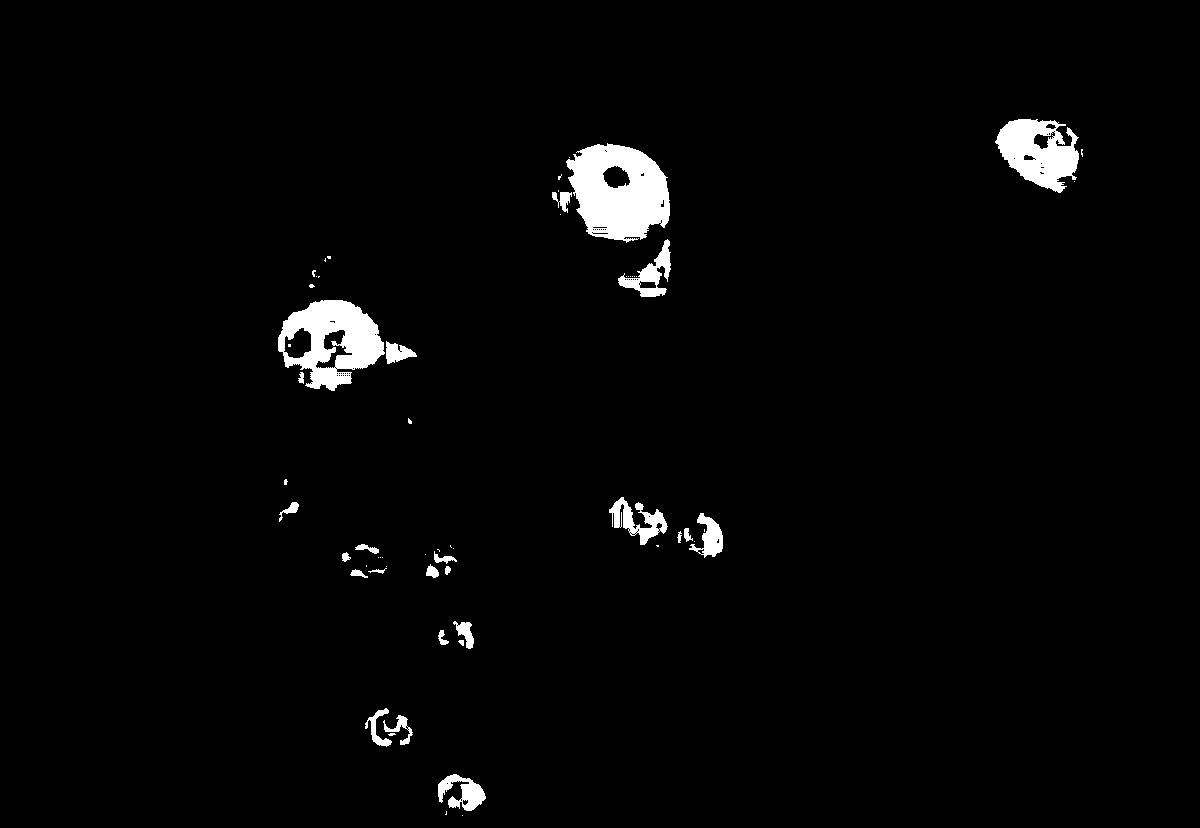

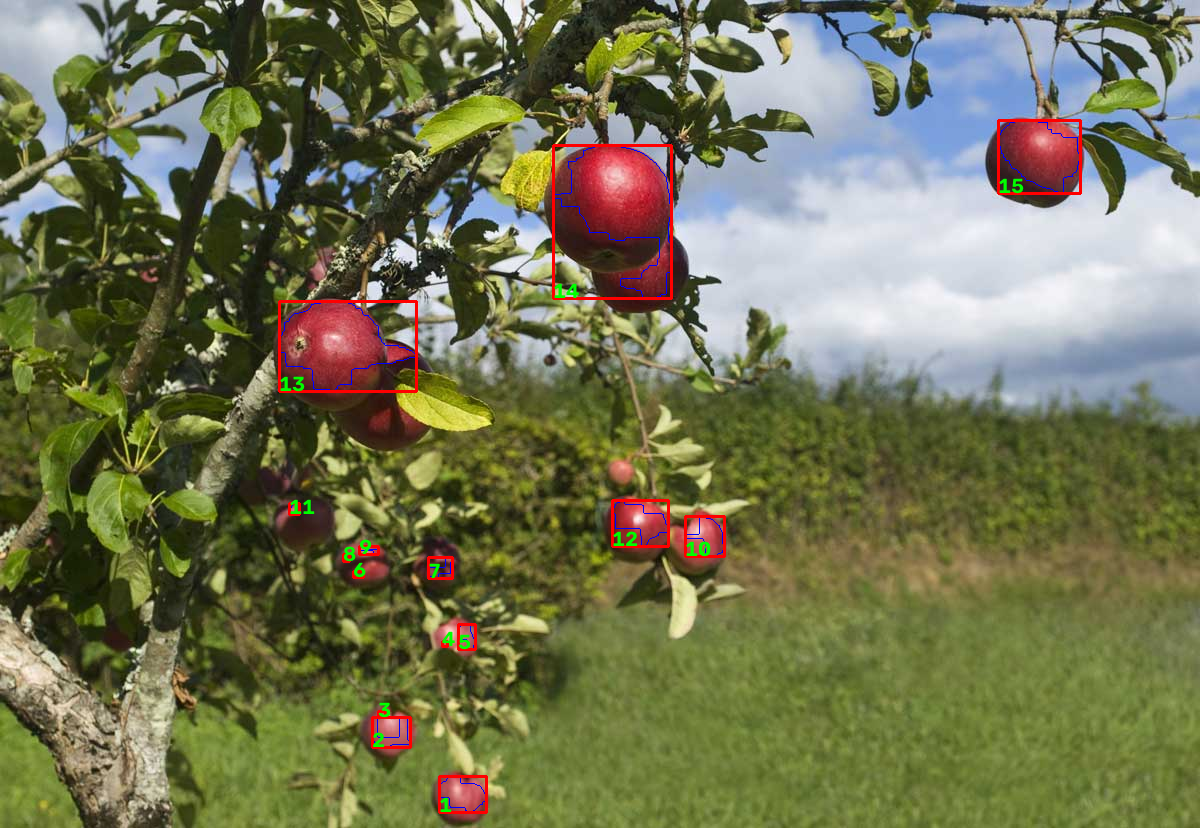

In [26]:
lowerBound = np.array([170, 100, 80])
upperBound = np.array([180, 256, 256])

kernelOpen = np.ones((5, 5))
kernelClose = np.ones((20, 20))

font = cv2.FONT_HERSHEY_SIMPLEX

img = cv2.imread('/content/apple.jpg')

# Convert image from BGR to HSV color space
imgHSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Create a binary mask based on color range thresholds
mask = cv2.inRange(imgHSV, lowerBound, upperBound)

# Apply morphological operations to remove noise
maskOpen = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernelOpen)
maskClose = cv2.morphologyEx(maskOpen, cv2.MORPH_CLOSE, kernelClose)

maskFinal = maskClose
conts, h = cv2.findContours(maskFinal.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

cv2.drawContours(img, conts, -1, (255, 0, 0), 1)
for i in range(len(conts)):
    x, y, w, h = cv2.boundingRect(conts[i])
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)
    cv2.putText(img, str(i + 1), (x, y + h), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

cv2_imshow(maskClose)
cv2_imshow(maskOpen)
cv2_imshow(mask)
cv2_imshow(img)

In [28]:
print( 'There were ',len(conts) ,' apples in this picture') #Print number of apples

There were  15  apples in this picture


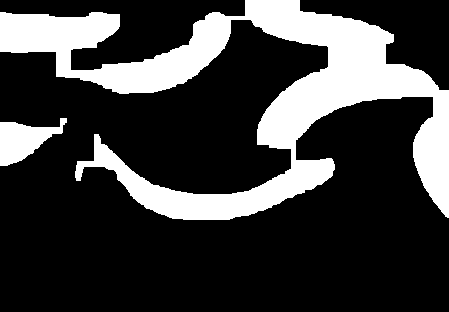

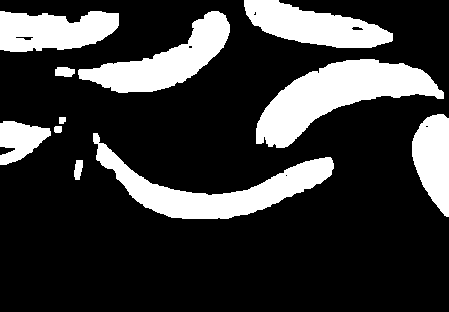

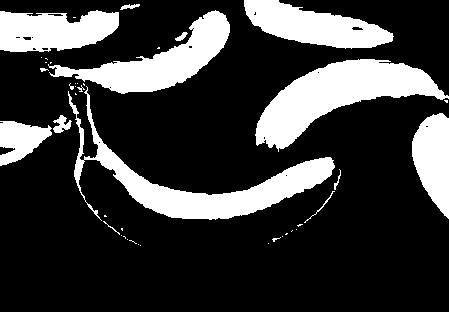

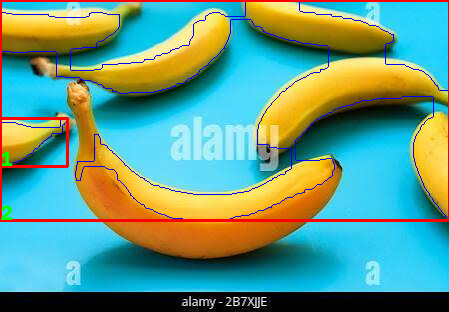

In [31]:
#Changed parameters to search for yellow bananas
lowerBound = np.array([20, 100, 100])
upperBound = np.array([30, 255, 255])

kernelOpen = np.ones((5, 5))
kernelClose = np.ones((20, 20))

font = cv2.FONT_HERSHEY_SIMPLEX

img = cv2.imread('/content/bananas.jfif')

# Convert image from BGR to HSV color space
imgHSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Create a binary mask based on color range thresholds
mask = cv2.inRange(imgHSV, lowerBound, upperBound)

# Apply morphological operations to remove noise
maskOpen = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernelOpen)
maskClose = cv2.morphologyEx(maskOpen, cv2.MORPH_CLOSE, kernelClose)

maskFinal = maskClose
contsChoice, h = cv2.findContours(maskFinal.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

cv2.drawContours(img, contsChoice, -1, (255, 0, 0), 1)
for i in range(len(contsChoice)):
    x, y, w, h = cv2.boundingRect(contsChoice[i])
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)
    cv2.putText(img, str(i + 1), (x, y + h), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

cv2_imshow(maskClose)
cv2_imshow(maskOpen)
cv2_imshow(mask)
cv2_imshow(img)

In [33]:
#Repeat the exercise with counting the items in an images of your choice.
print(f"Total elements counted in the alternative test image: {len(contsChoice)}")
#didnt work as well because elements where overlapping

Total elements counted in the alternative test image: 2


In [35]:
!apt-get update
!apt-get install texlive-xetex texlive-fonts-recommended texlive-latex-extra
!jupyter nbconvert /content/Assignment4_JuanTorres.ipynb --to pdf

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
texlive-xetex is already the newest version (2023.20240207-1).
texlive-fonts-recommended is already the newest version (2023.20240207-1).
texlive-latex-extra is already t

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
